In [412]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from scipy.interpolate import UnivariateSpline

In [413]:
bk_spacing = 0.25
b_spacing = 0.15
grid_search_bk_size = 5
grid_search_b_size = 1

In [414]:
ndRlist = [1, 2, 3, 4, 5, 10, 12, 15, 20, 30]
ndlist = [1, 2, 3, 4, 5, 10, 12, 15, 20, 30, 50, 60, 75, 100, 150, 300, 400, 750, 1000, 1500]
nslist = [60000, 30000, 20000, 15000, 12000, 6000, 5000, 4000, 3000, 2000, 1200, 1000, 800, 600, 400, 200, 150, 80, 60, 40]

In [415]:
df = pd.read_csv("../tmp_data/plot_data/tmp_df.csv")

In [416]:
mask = df.groupby(['nd', 'ndR'])['capacity'].transform('max') == df['capacity']

max_df = df[mask].reset_index(drop=True)

max_df[max_df['nd']==1]

max_df.to_csv("../tmp_data/plot_data/max_points_df.csv", index=False)

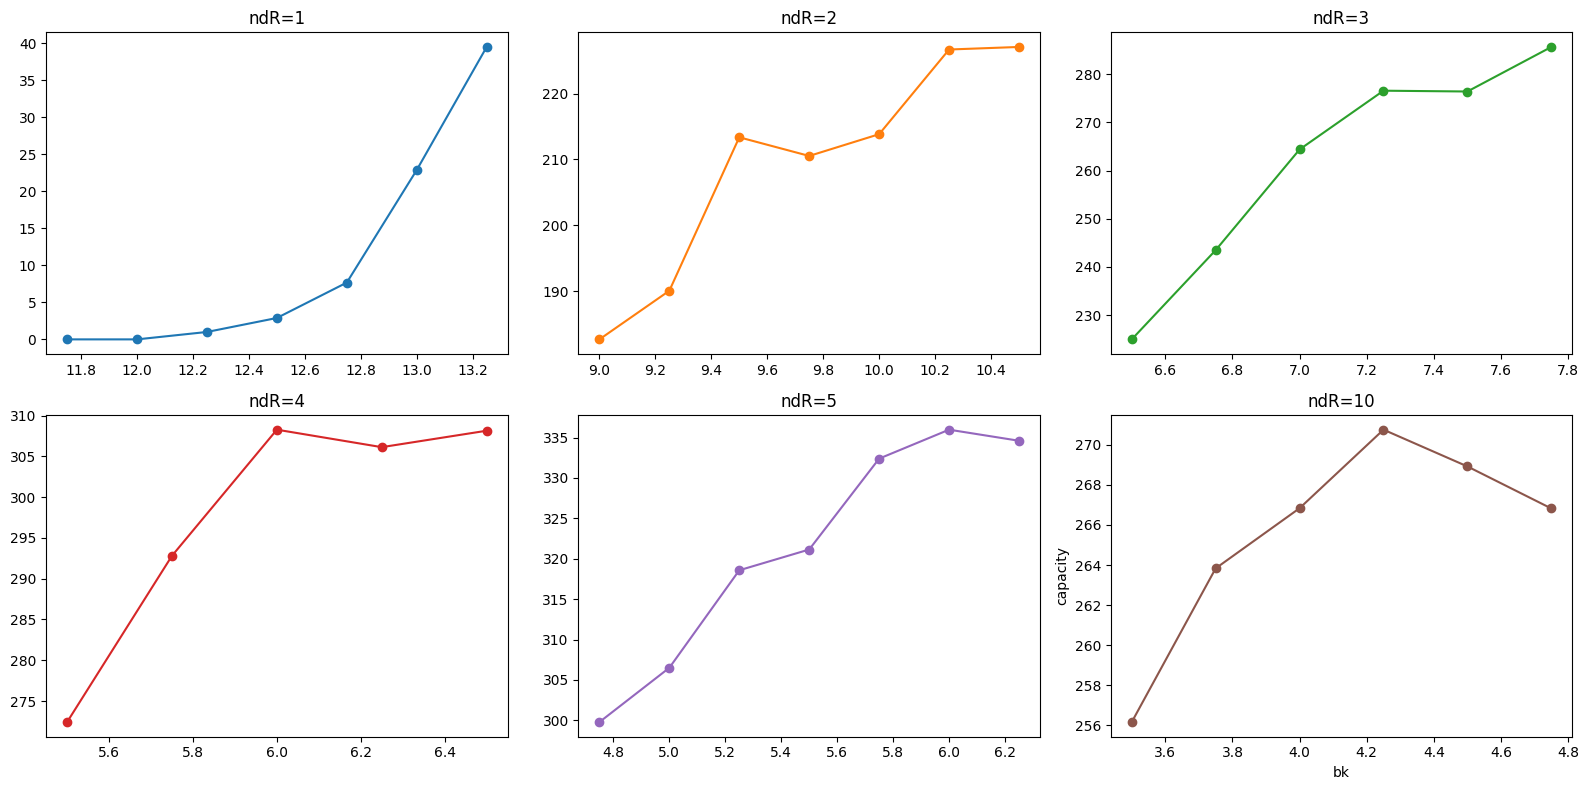

In [428]:
nd_plot = 20
fig, ax = plt.subplots(2, 3, figsize=(16, 8))

for ndR_idx, ndR in enumerate([1, 2, 3, 4, 5, 10]):
    try: 
        ax_i = ndR_idx//3
        ax_j = ndR_idx%3
        df_subset = df[df['nd'] == nd_plot]
        df_subset = df_subset[df_subset['ndR']==ndR]
        max_points = df_subset.nlargest(5, "capacity")
        # sns.scatterplot(ax=ax[ax_i, ax_j], data=df_subset, x='b', y='bk', color=f"C{ndR_idx}",  s=50, alpha=0.7, edgecolor='w')
        # sns.scatterplot(ax=ax[ax_i, ax_j], data=max_points.iloc[1:], x='b', y='bk', color=f"C{ndR_idx}",  s=150, edgecolor='black', linewidth=1.5,  marker='o', legend=False)
        # sns.scatterplot(ax=ax[ax_i, ax_j], data=max_points.iloc[[0]], x='b', y='bk', color=f"C{ndR_idx}",  s=150, edgecolor='black', linewidth=1.5,     marker='^', legend=False)
        df_subset = df_subset.sort_values("bk")
        ax[ax_i, ax_j].plot(df_subset["bk"], df_subset["capacity"], '-o', color=f'C{ndR_idx}')
        ax[ax_i, ax_j].set_title(f"ndR={ndR}")

    except: pass


# Add labels and title
plt.xlabel('bk')
plt.ylabel('capacity')

plt.tight_layout()
plt.show()

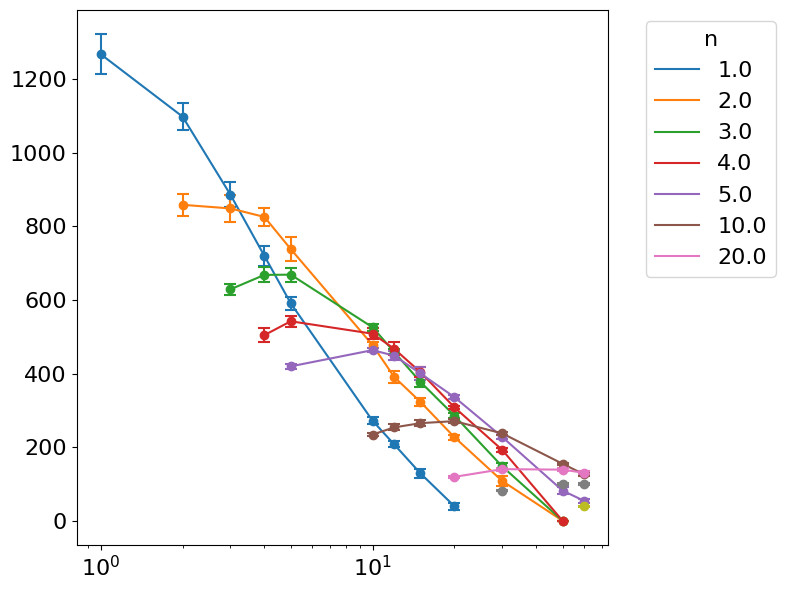

In [418]:
# Create the plot
plt.figure(figsize=(8, 6))

def smooth_spline(x, y, s_factor=0.0002):
    """
    Cubic smoothing spline with automatic smoothing chosen so that
    the mean‑squared error roughly equals s_factor × σ².
    If you have y‑errors, pass `w = 1/σ` to UnivariateSpline instead.
    """
    # sort, because spline routines need monotonic x
    idx = np.argsort(x)
    ymax = np.max(y)
    spline = UnivariateSpline(x[idx], y[idx], s=s_factor*len(x)*(ymax**2))
    return spline   

# Add error bars manually using plt.errorbar
for ndR_idx, ndR_value in enumerate(max_df['ndR'].unique()):
    subset = max_df[max_df['ndR'] == ndR_value]
    subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
    subset = subset.sort_values("nd")
    max_nd = subset['nd'].max()
    nd_plot_list = np.linspace(ndR_value, max_nd, int(max_nd-ndR_value))
    try:
        spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy())
        fitted_capacity = spline(np.log(nd_plot_list))

        # plt.plot(nd_plot_list, fitted_capacity, label=f"{ndR_value}", c=f"C{ndR_idx}") # Smoothed line
        plt.plot(subset['nd'], subset['capacity'], label=f"{ndR_value}", c=f"C{ndR_idx}") # Original points line
    except: pass

    plt.errorbar(
        x=subset['nd'],
        y=subset['capacity'],
        yerr=2*subset['sem'],
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )

    # plt.errorbar(
    #     x=subset['nd'],
    #     y=subset['capacity'],
    #     yerr=subset['sem'],
    #     fmt='-o',  
    #     capsize=4,
    #     capthick=1.5,
    #     elinewidth=1.5, 
    #     c=f"C{ndR_idx}"
    # )


# Set x-axis to log scale
plt.xscale('log')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Add labels and title
# plt.xlabel('Nd')
# plt.ylabel('Capacity')

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='n', fontsize=16, title_fontsize=16)

# plt.savefig("capacity_vs_nd_rho1.svg", bbox_inches='tight')

plt.tight_layout()

In [423]:
# check if any (nd, ndR) group have all-zero capacities

zero_mask = df.groupby(['nd', 'ndR'])['capacity'].apply(lambda x: (x <= 0).all())

# Convert the boolean Series to a list of valid (nd, ndR) tuples
zero_combinations = [idx for idx, is_zero in zero_mask.items() if is_zero]

# Convert to numpy array with 2 columns
nd_n_zero_combinations = np.array(zero_combinations, dtype=int) if zero_combinations else np.empty((0, 2), dtype=int)

# Display result
print("Zero-capacity combinations:")
print(nd_n_zero_combinations)

Zero-capacity combinations:
[[50  2]
 [50  3]
 [50  4]]


In [424]:
# Check (b, bk) grid alignment
tolerance = 1e-5  # Tolerance for grid alignment checks

# Iterate over each group
anomaly_records = []
for (nd, ndR), group in df.groupby(['nd', 'ndR']):
    anomaly_exist = False
    
    # Only check non-empty groups
    if len(group) == 0:
        continue
    
    # Use first point in group as reference (b0, bk0)
    b0 = group['b'].iloc[0]
    bk0 = group['bk'].iloc[0]
    
    # Check all points align to grid starting at (b0, bk0)
    for _, row in group.iterrows():
        b, bk = row['b'], row['bk']
        
        # Check b alignment
        ratio_b = (b - b0) / b_spacing
        if not np.isclose(ratio_b, np.round(ratio_b), atol=tolerance):
            anomaly_exist = True
            break
            
        # Check bk alignment
        ratio_bk = (bk - bk0) / bk_spacing
        if not np.isclose(ratio_bk, np.round(ratio_bk), atol=tolerance):
            anomaly_exist = True
            break
    
    
    if anomaly_exist:
        anomaly_records.append([nd, ndR])

print("anomoly [nd, ndR] record: \n", anomaly_records)

anomoly [nd, ndR] record: 
 []


In [425]:
# Grid search validation for bk, make sure the the top n largest grid points are not on the edge of the grid. 
# NOTICE THAT THE RESULTS MIGHT HAVE REPETITION. 

bcenter_bk_ndR_nd_ns_list = np.array([[0, 0, 0, 0, 0]])

min_distance_to_edge = 2 # the maximum point should be at least min_distance_to_edge away from the edge.

for nd_idx in range(len(ndlist)):
    nd = ndlist[nd_idx]
    ns = nslist[nd_idx]
    df_subset = df[df['nd'] == nd]
    

    for i, ndR in enumerate(ndRlist):
        try:
            df_tmp = df_subset[np.abs(df_subset["ndR"]-ndR)<1e-5]
            if df_tmp.empty:
                continue
            max_point = df_tmp.nlargest(1, "capacity")
            bk_max = np.max(df_tmp["bk"])
            bk_min = np.min(df_tmp["bk"])
            bk_best = np.array(max_point["bk"])
            dist_to_upper_edge = np.round((bk_max - bk_best) / bk_spacing).astype(int)[0]
            dist_to_lower_edge = np.round((bk_best - bk_min) / bk_spacing).astype(int)[0]
            if dist_to_lower_edge<min_distance_to_edge:
                tmplist = np.array([[0, bk_min-bk_spacing*j, ndR, nd, ns] for j in range(1, min_distance_to_edge-dist_to_lower_edge+1)])
                bcenter_bk_ndR_nd_ns_list = np.concatenate((bcenter_bk_ndR_nd_ns_list, tmplist), axis=0)
            if dist_to_upper_edge<min_distance_to_edge:
                tmplist = np.array([[0, bk_max+bk_spacing*j, ndR, nd, ns] for j in range(1, min_distance_to_edge-dist_to_upper_edge+1)])
                bcenter_bk_ndR_nd_ns_list = np.concatenate((bcenter_bk_ndR_nd_ns_list, tmplist), axis=0)
        except: 
            pass
bcenter_bk_ndR_nd_ns_list = bcenter_bk_ndR_nd_ns_list[1:]

In [426]:
# delelte rows if nd and ndR in nd_n_zero_combinations
rows_to_delete = []
for zero_combination in nd_n_zero_combinations:
    nd_zero, ndR_zero = zero_combination
    for row_idx, row in enumerate(bcenter_bk_ndR_nd_ns_list):
        b_center, bk_center, ndR_row, nd_row, ns_row = row
        if (np.abs(nd_row - nd_zero) < 1e-5) and (np.abs(ndR_row - ndR_zero) < 1e-5):
            rows_to_delete.append(row_idx)
bcenter_bk_ndR_nd_ns_list = np.delete(bcenter_bk_ndR_nd_ns_list, rows_to_delete, axis=0)

bcenter_bk_ndR_nd_ns_list

array([[0.000e+00, 1.175e+01, 1.000e+00, 1.000e+01, 6.000e+03],
       [0.000e+00, 1.200e+01, 1.000e+00, 1.000e+01, 6.000e+03],
       [0.000e+00, 1.250e+01, 1.000e+00, 1.200e+01, 5.000e+03],
       [0.000e+00, 1.275e+01, 1.000e+00, 1.200e+01, 5.000e+03],
       [0.000e+00, 1.300e+01, 1.000e+00, 1.500e+01, 4.000e+03],
       [0.000e+00, 1.325e+01, 1.000e+00, 1.500e+01, 4.000e+03],
       [0.000e+00, 1.350e+01, 1.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 1.375e+01, 1.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 1.075e+01, 2.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 1.100e+01, 2.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 8.000e+00, 3.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 8.250e+00, 3.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 6.500e+00, 5.000e+00, 2.000e+01, 3.000e+03],
       [0.000e+00, 4.750e+00, 2.000e+01, 2.000e+01, 3.000e+03],
       [0.000e+00, 1.125e+01, 2.000e+00, 3.000e+01, 2.000e+03],
       [0.000e+00, 1.150e+01, 2.000e+00,

In [376]:
"generate 2d tmplist where each entry is b_best, bk_best, ndR, nd, ns"
bcenter_bk_ndR_nd_ns_list = np.array([[0, 0, 0, 0, 0]])
for nd_idx in range(len(ndlist)):
    nd = ndlist[nd_idx]
    ns = nslist[nd_idx]
    df_tmp = df[df["nd"]==nd]
    idx_nd = df_tmp.groupby('ndR')['capacity'].idxmax()
    max_df = df_tmp.loc[idx_nd]
    max_df["ns"] = ns

    for i, ndR in enumerate(ndRlist):
        try:
            tmp_df = max_df[np.abs(max_df["ndR"]-ndR)<1e-5]
            tmplist = np.array([tmp_df["b"], tmp_df["bk"], tmp_df["ndR"], tmp_df["nd"], tmp_df["ns"]])
            tmplist = tmplist.reshape((-1, 5))
            tmplist = np.array([[tmplist[idx1] for _ in range(grid_search_bk_size)] for idx1 in range(len(tmplist))])
            tmplist[:, :, 1] += (np.arange(0, grid_search_bk_size) - grid_search_bk_size//2)*bk_spacing
            tmplist = tmplist.reshape((-1, 5))
            bcenter_bk_ndR_nd_ns_list = np.concatenate((bcenter_bk_ndR_nd_ns_list, tmplist), axis=0)
        except: 
            pass
bcenter_bk_ndR_nd_ns_list = bcenter_bk_ndR_nd_ns_list[1:]

In [395]:
"generate 2d tmplist where each entry is b_best, bk_best, ndR, nd, ns for a given nd"

nd = 50

bcenter_bk_ndR_nd_ns_list = np.array([[0, 0, 0, 0, 0]])
nd_idx = ndlist.index(nd)
ns = nslist[nd_idx]
next_nd = ndlist[nd_idx+1]
next_ns = nslist[nd_idx+1]
df_tmp = df[df['nd']==nd]
idx_nd = df_tmp.groupby('ndR')['capacity'].idxmax()
max_df = df_tmp.loc[idx_nd]
max_df["ns"] = ns

for i, ndR in enumerate(ndRlist):
    if ndR in [1, 2, 3, 4]:
        continue
    try:
        tmp_df = max_df[np.abs(max_df["ndR"]-ndR)<1e-5]
        tmplist = np.array([tmp_df["b"], tmp_df["bk"], tmp_df["ndR"], tmp_df["nd"], tmp_df["ns"]])
        tmplist[-2] = next_nd
        tmplist[-1] = next_ns
        # tmplist[1] += bk_spacing * 1
        tmplist = tmplist.reshape((-1, 5))
        tmplist = np.array([[tmplist[idx1] for _ in range(grid_search_bk_size)] for idx1 in range(len(tmplist))])
        tmplist[:, :, 1] += (np.arange(0, grid_search_bk_size) - grid_search_bk_size//2)*bk_spacing
        tmplist = tmplist.reshape((-1, 5))
        bcenter_bk_ndR_nd_ns_list = np.concatenate((bcenter_bk_ndR_nd_ns_list, tmplist), axis=0)
    except: 
        pass

bcenter_bk_ndR_nd_ns_list = bcenter_bk_ndR_nd_ns_list[1:]

In [396]:
bcenter_bk_ndR_nd_ns_list

array([[   0.  ,    6.25,    5.  ,   60.  , 1000.  ],
       [   0.  ,    6.5 ,    5.  ,   60.  , 1000.  ],
       [   0.  ,    6.75,    5.  ,   60.  , 1000.  ],
       [   0.  ,    7.  ,    5.  ,   60.  , 1000.  ],
       [   0.  ,    7.25,    5.  ,   60.  , 1000.  ],
       [   0.  ,    4.5 ,   10.  ,   60.  , 1000.  ],
       [   0.  ,    4.75,   10.  ,   60.  , 1000.  ],
       [   0.  ,    5.  ,   10.  ,   60.  , 1000.  ],
       [   0.  ,    5.25,   10.  ,   60.  , 1000.  ],
       [   0.  ,    5.5 ,   10.  ,   60.  , 1000.  ],
       [   0.  ,    4.  ,   20.  ,   60.  , 1000.  ],
       [   0.  ,    4.25,   20.  ,   60.  , 1000.  ],
       [   0.  ,    4.5 ,   20.  ,   60.  , 1000.  ],
       [   0.  ,    4.75,   20.  ,   60.  , 1000.  ],
       [   0.  ,    5.  ,   20.  ,   60.  , 1000.  ],
       [   0.  ,    3.75,   30.  ,   60.  , 1000.  ],
       [   0.  ,    4.  ,   30.  ,   60.  , 1000.  ],
       [   0.  ,    4.25,   30.  ,   60.  , 1000.  ],
       [   0.  ,    4.5 ,   

In [427]:
np.savetxt("../tmp_data/tmp.csv", bcenter_bk_ndR_nd_ns_list, fmt=['%.3f', '%.3f', '%d', '%d', '%d'], delimiter=',')

In [686]:
# totalN = 60000
# params_list = np.array([[point[2], 60000//point[2], point[1], point[0], point[3], -1, 20240305] for point in b_bk_nd_ndR_list])
# np.savetxt("../tmp_data_new/params_list_tmp_tmp.csv", params_list, fmt=['%d', '%d', '%.3f', '%.3f', '%d', '%.3f', '%d'], delimiter=',')